In [2]:
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.messages import RemoveMessage

In [3]:
load_dotenv()

True

In [4]:
# Model
model= ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite"
)

In [5]:
def chat(state: MessagesState):
    response = model.invoke(state["messages"])
    return {"messages": [response]}

def delete_old_messages(state: MessagesState):
    msgs = state["messages"]

    # if more than 10 messages, delete the earliest 6
    if len(msgs) > 10:
        to_remove = msgs[:6]
        return {"messages": [RemoveMessage(id=m.id) for m in to_remove]}

    return {}

In [6]:
builder = StateGraph(MessagesState)
builder.add_node("chat", chat)
builder.add_node("cleanup", delete_old_messages)

In [7]:
builder.add_edge(START, "chat")
builder.add_edge("chat", "cleanup")   # run deletion after each response
builder.add_edge("cleanup", "__end__")

In [8]:
graph = builder.compile(checkpointer=InMemorySaver())

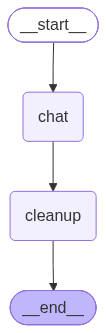

In [9]:
graph

In [10]:
config = {"configurable": {"thread_id": "t1"}}

In [11]:
# Run multiple turns
graph.invoke({"messages": [{"role": "user", "content": "Hi, I'm Nitish"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "Tell me about LangGraph"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "Now explain checkpointers"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is Langchain"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is Quantum Mechanics"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is Gen AI"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is my name"}]}, config)

{'messages': [HumanMessage(content='What is Langchain', additional_kwargs={}, response_metadata={}, id='a55faf9c-31fc-4d25-828a-cbed70b17971'),
  AIMessage(content=[{'type': 'text', 'text': '**LangChain** is an open-source development framework designed to make it easier to build applications using Large Language Models (LLMs) like GPT-4, Claude, or open-source models like Llama.\n\nIf LLMs are the powerful "engines," LangChain is the "chassis, steering wheel, and dashboard" that helps you build a working vehicle out of them.\n\nHere is a breakdown of what LangChain is and why developers use it:\n\n---\n\n### 1. The Core Problem It Solves\nOut of the box, an LLM API (like OpenAI\'s API) is essentially a stateless text-in, text-out machine. It doesn\'t know about your private company data, it can\'t browse the live internet, it can\'t execute code, and it forgets everything you said the moment you start a new request.\n\nBuilding all of that plumbing from scratch—handling prompt formatt

In [12]:
snap = graph.get_state(config)
print("Stored messages after cleanup:", len(snap.values["messages"]))

Stored messages after cleanup: 8
